# 01 · Data Quality Checks & Cleaning

**Goal:** turn the raw DataCo export (180,519 order lines, 53 columns) into a clean, trustworthy table for delivery-risk analysis and Power BI.

**Source:** [DataCo Smart Supply Chain for Big Data Analysis, Kaggle](https://www.kaggle.com/datasets/shashwatwork/dataco-smart-supply-chain-for-big-data-analysis) · global sporting-goods retailer · Jan 2015 to Jan 2018

All checks are written in SQL (DuckDB).

In [1]:
import duckdb
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = (ROOT / "data" / "raw" / "DataCoSupplyChainDataset.csv").as_posix()
PROCESSED = ROOT / "data" / "processed"
IMAGES = ROOT / "images"
PROCESSED.mkdir(parents=True, exist_ok=True)
IMAGES.mkdir(parents=True, exist_ok=True)

con = duckdb.connect()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 30)

## 1. Issue found: the file is not UTF-8

Reading the file with the default UTF-8 encoding fails, because it contains Spanish and other accented place names (e.g. `Rajastán`) saved in a legacy Windows encoding.

In [2]:
try:
    con.sql(f"SELECT COUNT(*) FROM read_csv('{RAW}')").fetchall()
    print("UTF-8 read worked")
except Exception as e:
    print("UTF-8 read failed ->", type(e).__name__, str(e)[:160])

UTF-8 read failed -> InvalidInputException Invalid Input Error: CSV Error on Line: 3
Original Line: 
DEBIT,3,4,91.25,314.6400146,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20


The obvious guess is Latin-1, but the file also contains bytes `0x8A`, `0x8E` and `0x92` (`Š`, `Ž`, `’`), which only exist in **Windows-1252**. Python converts it once to a UTF-8 copy, which DuckDB then reads cleanly. The copy goes to `data/interim/` and is git-ignored.

In [3]:
INTERIM = ROOT / "data" / "interim"
INTERIM.mkdir(parents=True, exist_ok=True)
UTF8 = (INTERIM / "dataco_utf8.csv").as_posix()

raw_bytes = open(RAW, "rb").read()
special = sorted({hex(b) for b in raw_bytes if 0x80 <= b <= 0x9F})
print("Bytes only valid in Windows-1252:", special)
with open(UTF8, "w", encoding="utf-8", newline="") as f:
    f.write(raw_bytes.decode("cp1252"))
print("Converted to UTF-8:", UTF8)

Bytes only valid in Windows-1252: ['0x8a', '0x8e', '0x92']


Converted to UTF-8: C:/Users/SUDHEER/Downloads/DataAnalytics/supply-chain-risk-analysis/data/interim/dataco_utf8.csv


In [4]:
con.sql(f"""
    CREATE OR REPLACE TABLE raw AS
    SELECT * FROM read_csv('{UTF8}', header = true,
                           types = {{'order date (DateOrders)': 'VARCHAR',
                                     'shipping date (DateOrders)': 'VARCHAR'}})
""")
con.sql("SELECT COUNT(*) AS rows, COUNT(DISTINCT \"Order Id\") AS orders, COUNT(DISTINCT \"Order Item Id\") AS order_lines FROM raw").df()

,rows,orders,order_lines
0,180519,65752,180519


Each row is one **order line** (one product in an order). `Order Item Id` is unique, so it is the primary key: 180,519 lines across 65,752 orders.

## 2. Columns that carry no information

In [5]:
con.sql("""
    SELECT COUNT(DISTINCT "Customer Email")                         AS distinct_emails,
           COUNT(DISTINCT "Customer Password")                      AS distinct_passwords,
           ROUND(100.0 * COUNT(*) FILTER (WHERE "Product Description" IS NULL) / COUNT(*), 1) AS pct_null_description,
           ROUND(100.0 * COUNT(*) FILTER (WHERE "Order Zipcode" IS NULL) / COUNT(*), 1)       AS pct_null_order_zip,
           COUNT(DISTINCT "Product Status")                         AS distinct_product_status
    FROM raw
""").df()

,distinct_emails,distinct_passwords,pct_null_description,pct_null_order_zip,distinct_product_status
0,1,1,100.00,86.20,1


- **Email and password** are masked (`XXXXXXXXX`). They are personal data with no analytical value, so they are dropped. Names and street addresses are dropped for the same reason (data minimisation).
- **Product Description** is 100% empty and **Order Zipcode** is 86% empty, so both are dropped.
- **Product Status** has one value, so it is dropped.

## 3. Duplicate columns

Several columns look like copies of each other. Count how many rows differ before dropping one of each pair:

In [6]:
con.sql("""
    SELECT SUM(CASE WHEN "Benefit per order"  <> "Order Profit Per Order"   THEN 1 ELSE 0 END) AS benefit_vs_profit,
           SUM(CASE WHEN "Sales per customer" <> "Order Item Total"         THEN 1 ELSE 0 END) AS sales_per_cust_vs_item_total,
           SUM(CASE WHEN "Customer Id"        <> "Order Customer Id"        THEN 1 ELSE 0 END) AS customer_id_pair,
           SUM(CASE WHEN "Product Price"      <> "Order Item Product Price" THEN 1 ELSE 0 END) AS price_pair,
           SUM(CASE WHEN "Category Id"        <> "Product Category Id"      THEN 1 ELSE 0 END) AS category_id_pair
    FROM raw
""").df()

,benefit_vs_profit,sales_per_cust_vs_item_total,customer_id_pair,price_pair,category_id_pair
0,0.00,0.00,0.00,0.00,0.00


All five pairs match on every row, so one column of each pair is kept.

## 4. Can the "late" flag be trusted?

`Late_delivery_risk` drives the whole analysis, so it is checked against the raw shipping days.

In [7]:
con.sql("""
    SELECT "Delivery Status",
           SUM("Late_delivery_risk")                                                        AS flagged_late,
           SUM(CASE WHEN "Days for shipping (real)" > "Days for shipment (scheduled)" THEN 1 ELSE 0 END) AS actually_late,
           COUNT(*)                                                                         AS lines
    FROM raw
    GROUP BY 1
    ORDER BY lines DESC
""").df()

,Delivery Status,flagged_late,actually_late,lines
0,Late delivery,"98,977.00","98,977.00",98977
1,Advance shipping,0.00,0.00,41592
2,Shipping on time,0.00,0.00,32196
3,Shipping canceled,0.00,"4,423.00",7754


- For every shipped order, the flag equals **actual days > promised days** exactly, so the metric is reliable.
- **Cancelled shipments** (7,754 lines) never shipped, yet some have "days" values. They are excluded from on-time metrics with an `is_cancelled` flag; otherwise they would distort the late rate.

## 5. Volume over time: a data caveat

In [8]:
monthly = con.sql("""
    SELECT CAST(date_trunc('month', strptime("order date (DateOrders)", '%m/%d/%Y %H:%M')) AS DATE) AS month,
           COUNT(*)                      AS order_lines,
           COUNT(DISTINCT "Category Name") AS categories_sold
    FROM raw
    GROUP BY 1 ORDER BY 1
""").df()
monthly.tail(8)

,month,order_lines,categories_sold
29,2017-06-01,4951,24
30,2017-07-01,5318,24
31,2017-08-01,5305,24
32,2017-09-01,5189,26
33,2017-10-01,2255,20
34,2017-11-01,2055,8
35,2017-12-01,2124,14
36,2018-01-01,2123,10


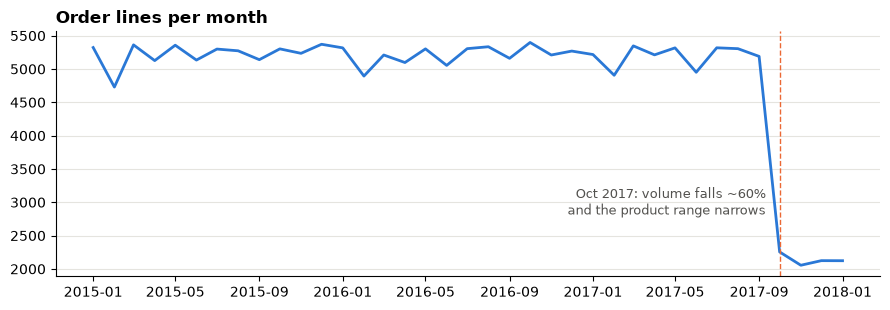

In [9]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(monthly["month"], monthly["order_lines"], color="#2a78d6", linewidth=2)
ax.axvline(pd.Timestamp("2017-10-01"), color="#eb6834", linewidth=1, linestyle="--")
ax.annotate("Oct 2017: volume falls ~60%\nand the product range narrows", (pd.Timestamp("2017-10-01"), 3000),
            xytext=(-10, 0), textcoords="offset points", ha="right", va="center", color="#52514e", fontsize=9)
ax.set_title("Order lines per month", loc="left", fontweight="bold")
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.grid(axis="y", color="#e5e4df"); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(IMAGES / "00_monthly_volume.png", dpi=150, bbox_inches="tight"); plt.show()

From October 2017, volume drops by about 60% and far fewer product categories are sold. This looks like a change in what was captured (a catalogue or system change), not a real collapse in demand. **Decision:** keep these rows for delivery-performance analysis (the shipping process is the same) but **don't read revenue trends across that break**. It is noted as a caveat in the README.

## 6. Build the clean table

In [10]:
con.sql("""
    CREATE OR REPLACE TABLE orders_clean AS
    SELECT "Order Item Id"                                         AS order_item_id,
           "Order Id"                                              AS order_id,
           strptime("order date (DateOrders)",    '%m/%d/%Y %H:%M') AS order_ts,
           CAST(strptime("order date (DateOrders)", '%m/%d/%Y %H:%M') AS DATE) AS order_date,
           CAST(date_trunc('month', strptime("order date (DateOrders)", '%m/%d/%Y %H:%M')) AS DATE) AS order_month,
           strptime("shipping date (DateOrders)", '%m/%d/%Y %H:%M') AS ship_ts,
           "Type"                                                  AS payment_type,
           "Order Status"                                          AS order_status,
           "Delivery Status"                                       AS delivery_status,
           "Shipping Mode"                                         AS shipping_mode,
           "Days for shipment (scheduled)"                         AS days_promised,
           "Days for shipping (real)"                              AS days_actual,
           "Days for shipping (real)" - "Days for shipment (scheduled)" AS delay_days,
           "Late_delivery_risk"                                    AS is_late,
           "Delivery Status" = 'Shipping canceled'                 AS is_cancelled,
           "Order Status" = 'SUSPECTED_FRAUD'                      AS is_suspected_fraud,
           "Market"                                                AS market,
           "Order Region"                                          AS order_region,
           "Order Country"                                         AS order_country,
           "Order City"                                            AS order_city,
           "Customer Id"                                           AS customer_id,
           "Customer Segment"                                      AS customer_segment,
           "Department Name"                                       AS department,
           "Category Name"                                         AS category,
           "Product Name"                                          AS product_name,
           "Order Item Quantity"                                   AS quantity,
           "Order Item Discount Rate"                              AS discount_rate,
           "Sales"                                                 AS gross_sales,
           "Order Item Total"                                      AS net_sales,
           "Order Profit Per Order"                                AS profit
    FROM raw
""")
con.sql("SELECT COUNT(*) AS rows, COUNT(*) FILTER (WHERE NOT is_cancelled) AS shipped_rows FROM orders_clean").df()

,rows,shipped_rows
0,180519,172765


## 7. Validate and save

In [11]:
con.sql("""
    SELECT MIN(order_date) AS first_order, MAX(order_date) AS last_order,
           MIN(days_actual) AS min_days, MAX(days_actual) AS max_days,
           SUM(CASE WHEN ship_ts < order_ts THEN 1 ELSE 0 END) AS shipped_before_ordered,
           ROUND(SUM(net_sales)) AS net_sales, ROUND(SUM(profit)) AS profit
    FROM orders_clean
""").df()

,first_order,last_order,min_days,max_days,shipped_before_ordered,net_sales,profit
0,2015-01-01,2018-01-31,0,6,0.00,"33,054,402.00","3,966,903.00"


In [12]:
parquet = (PROCESSED / "supply_chain_clean.parquet").as_posix()
csv = (PROCESSED / "supply_chain_clean.csv").as_posix()
con.sql(f"COPY orders_clean TO '{parquet}' (FORMAT PARQUET)")
con.sql(f"COPY orders_clean TO '{csv}' (HEADER, DELIMITER ',')")
print("Saved parquet (committed to Git) and CSV (for Power BI, git-ignored)")

Saved parquet (committed to Git) and CSV (for Power BI, git-ignored)


## Summary

| Issue | Fix |
|---|---|
| File not UTF-8 (Windows-1252) | Converted to UTF-8 before loading |
| Masked PII (email, password), names, street | Dropped (no analytical value; data minimisation) |
| Empty or constant columns | Dropped |
| 5 duplicate column pairs | Verified identical, kept one of each |
| Cancelled shipments have "days" values | `is_cancelled` flag; excluded from delivery metrics |
| Volume and catalogue break from Oct 2017 | Kept, flagged as a caveat for trend reading |

The result is 180,519 rows × 30 columns, saved as Parquet (small enough for GitHub) and CSV (for Power BI).